<a href="https://colab.research.google.com/github/shrijav22/ML_LAB_2026-2027/blob/main/K_Means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



**K-Means clustering** is a popular unsupervised learning algorithm used for clustering. Its goal is to group a given dataset into a specified number ('k') of clusters. The main idea is that data points within the same cluster are similar to each other, and data points in different clusters are dissimilar.

The "means" in K-Means refers to the centroids (the average location or "center" of a cluster), which are used to define the cluster's position.

**How the Algorithm Works**

The algorithm works iteratively in a few simple steps to find the best cluster groupings.

*Choose 'k':* First, you must decide how many clusters (k) you want to find. This is a crucial parameter that you provide to the algorithm.

*Initialize Centroids: *The algorithm randomly places 'k' points (the centroids) in the feature space. These serve as the initial "guesses" for the center of each cluster.

*Assign Points (Assignment Step)*: The algorithm goes through each data point and calculates its distance to every one of the 'k' centroids (usually using Euclidean distance). Each data point is then assigned to the cluster of its nearest centroid.

*Update Centroids (Update Step):* Once all data points are assigned to a cluster, the algorithm recalculates the position of the 'k' centroids. The new position for a centroid is the mean (average) of all the data points assigned to its cluster.

***Repeat: ***The algorithm repeats Steps 3 and 4 (Assignment and Update) iteratively. Points get reassigned to the new, updated centroids, and then the centroids are updated again based on their new points.

This process continues until the algorithm converges, which means the cluster assignments stop changing and the centroids no longer move significantly.


Cluster assignments (first 10): [0 2 2 2 2 2 0 3 2 0]
Location of cluster centers:
 [[ 0.28344568  0.69088937]
 [-1.28519556  0.8177972 ]
 [ 0.31745463 -1.13877913]
 [-4.56527454  0.91572913]]


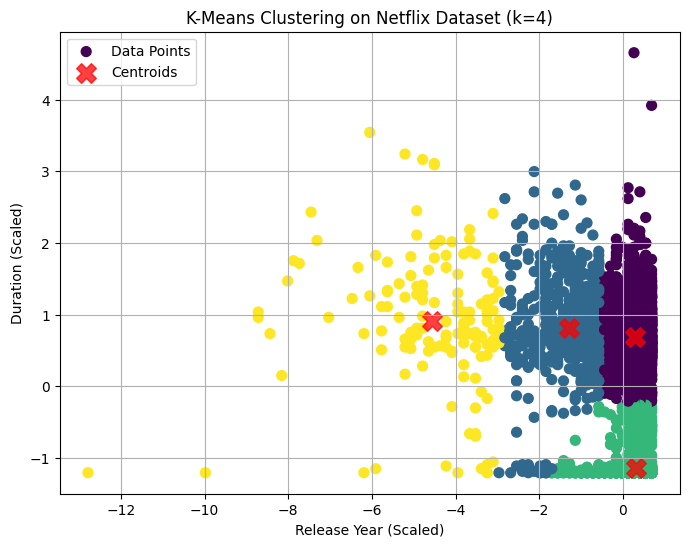

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load the Dataset
data = pd.read_csv("netflix_titles.csv")

# 2. Select Features
# Convert duration into numerical values (minutes or seasons)
data['duration_value'] = pd.to_numeric(
    data['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

# Select two numerical features
X = data[['release_year', 'duration_value']]

# 3. Handle Missing Values
X = X.dropna()

# 4. Scale the Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Create and Train the K-Means Model
# We are looking for 4 clusters
kmeans = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

# Fit the model and predict clusters
y_kmeans = kmeans.fit_predict(X_scaled)

# 6. Get Cluster Information
centers = kmeans.cluster_centers_

print("Cluster assignments (first 10):", y_kmeans[:10])

print("Location of cluster centers:\n", centers)

# 7. Visualize the Results
plt.figure(figsize=(8, 6))

# Plot data points
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_kmeans,
    s=50,
    cmap='viridis',
    label='Data Points'
)

# Plot cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=200,
    alpha=0.75,
    marker='X',
    label='Centroids'
)

plt.title('K-Means Clustering on Netflix Dataset (k=4)')
plt.xlabel('Release Year (Scaled)')
plt.ylabel('Duration (Scaled)')
plt.legend()
plt.grid(True)
plt.show()
